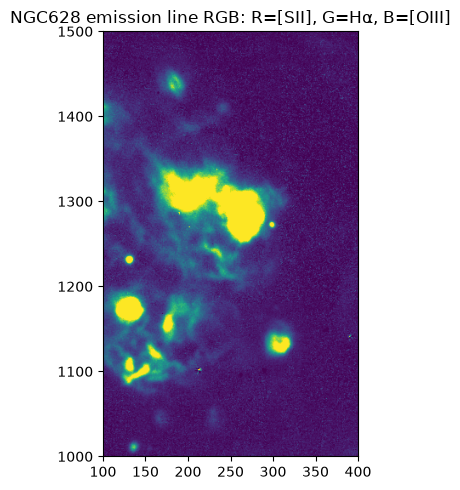

In [19]:
import os
import numpy as np
import pandas as pd
from scipy import ndimage as ndi
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors

from astropy.io import fits
from astropy.wcs import WCS
from astropy.stats import sigma_clipped_stats
from astropy.coordinates import SkyCoord
import astropy.units as u

def percentile_norm(img, pmin=1, pmax=99):
    x = np.array(img, dtype=float, copy=True)
    x[~np.isfinite(x)] = np.nan
    lo, hi = np.nanpercentile(x, [pmin, pmax])
    x = (x - lo) / (hi - lo)
    x = np.clip(x, 0, 1)
    return x 
    
path = "M33_MAPS.fits"
hdul = fits.open(path, memmap=True)

ha = hdul["HA6562_FLUX"].data
hb = hdul["HB4861_FLUX"].data
oiii = hdul["OIII5006_FLUX"].data
nii = hdul["NII6583_FLUX"].data

ha_err = hdul["HA6562_FLUX_ERR"].data
hb_err = hdul["HB4861_FLUX_ERR"].data
oiii_err = hdul["OIII5006_FLUX_ERR"].data
nii_err = hdul["NII6583_FLUX_ERR"].data


plt.figure(figsize=(10, 5))
plt.imshow(percentile_norm(oiii), origin="lower")
plt.title("NGC628 emission line RGB: R=[SII], G=H\u03B1, B=[OIII]")
plt.xlim(100,400)
plt.ylim(1000,1500)
plt.tight_layout()
plt.show()